# Component A, Question 1: Sensor Simulation and Perception Pipeline

This notebook processes **real sensor data logged from the Webots simulation**
(`webots/worlds/component_a.wbt`). An e-puck robot with a 360° LiDAR and a
160×120 camera explored a 1.5 m × 1.5 m arena containing five grey box
obstacles and three coloured cylinder landmarks (red, green, blue).

**Pipeline:**
1. **Camera:** HSV colour segmentation to detect and identify landmarks, and a pinhole model to convert detections to bearings
2. **LiDAR:** validity checking, then log-odds occupancy-grid mapping (a median filter was tested and rejected; see Section 4)
3. **Fusion:** camera bearing and identity combined with LiDAR range to give labelled landmark positions, merged into one semantic occupancy grid
4. **Evaluation:** against the true world layout exported by the Webots supervisor

The fused grid is saved to `outputs/fused_map.npz` for the path planner in Question 2.

In [1]:
import json
import math
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle, Rectangle
from scipy.ndimage import binary_dilation, binary_erosion

from perception import colour_mask, detect_landmarks, draw_detections
from lidar_processing import (OccupancyGrid, clean_scan, ground_truth_grid,
                              load_dataset, ray_angles, scan_to_points)
from sensor_fusion import (LANDMARK_CODES, aggregate_landmarks,
                           build_fused_map, fuse_detection)

DATA_DIR = Path("../../webots/data")
IMAGE_DIR = DATA_DIR / "images"
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

# The repository stores camera frames as images.zip (GitHub's web upload
# limit is 100 files), so extract them on first run.
if not IMAGE_DIR.is_dir():
    import zipfile
    with zipfile.ZipFile(DATA_DIR / "images.zip") as archive:
        archive.extractall(DATA_DIR,
                           [m for m in archive.namelist()
                            if m.startswith("images/")])
print("Camera frames:", len(list(IMAGE_DIR.glob("*.png"))))

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})

Camera frames: 182


## 1. Load the Webots dataset

In [2]:
scans, raw_ranges, truth = load_dataset(DATA_DIR)

LIDAR_FOV = truth["lidar"]["fov_rad"]
MAX_RANGE = truth["lidar"]["max_range_m"]
CAM_FOV = truth["camera"]["fov_rad"]
LANDMARK_RADIUS = truth["landmarks"][0]["radius"]
angles = ray_angles(raw_ranges.shape[1], LIDAR_FOV)

summary = pd.DataFrame({
    "Quantity": ["Samples", "Duration (s)", "Sampling period (s)",
                 "LiDAR rays / FOV", "LiDAR max range (m)",
                 "Camera resolution / FOV", "Obstacles", "Landmarks"],
    "Value": [len(scans), round(scans.time_s.max(), 1),
              round(scans.time_s.diff().median(), 2),
              f"{raw_ranges.shape[1]} / {math.degrees(LIDAR_FOV):.0f} deg",
              MAX_RANGE,
              f"{truth['camera']['width']}x{truth['camera']['height']} / "
              f"{math.degrees(CAM_FOV):.0f} deg",
              len(truth["obstacles"]), len(truth["landmarks"])],
})
summary

,Quantity,Value
0,Samples,182
1,Duration (s),89.8
2,Sampling period (s),0.5
3,LiDAR rays / FOV,360 / 360 deg
4,LiDAR max range (m),1.5
5,Camera resolution / FOV,160x120 / 48 deg
6,Obstacles,5
7,Landmarks,3


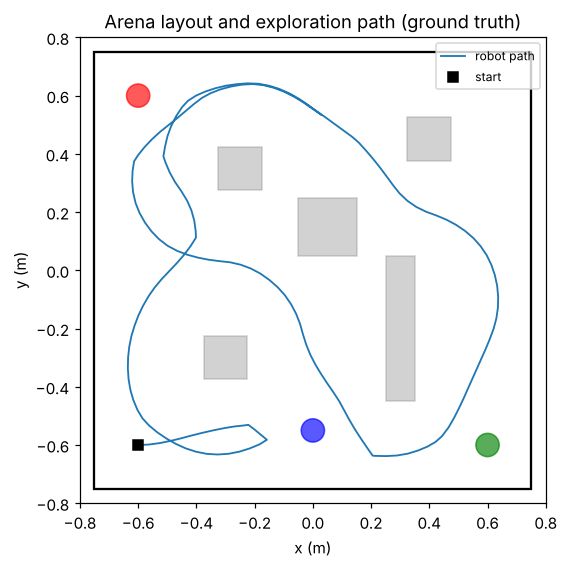

In [3]:
def draw_world(ax, truth, alpha=0.35):
    """Draw the true arena, obstacles and landmarks."""
    hx, hy = truth["arena"]["size_x"] / 2, truth["arena"]["size_y"] / 2
    ax.add_patch(Rectangle((-hx, -hy), 2 * hx, 2 * hy, fill=False, lw=1.5))
    for o in truth["obstacles"]:
        ax.add_patch(Rectangle((o["x"] - o["size_x"] / 2,
                                o["y"] - o["size_y"] / 2),
                               o["size_x"], o["size_y"],
                               color="grey", alpha=alpha))
    for lm in truth["landmarks"]:
        ax.add_patch(Circle((lm["x"], lm["y"]), lm["radius"],
                            color=lm["colour"], alpha=alpha + 0.3))
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")


fig, ax = plt.subplots(figsize=(5.5, 5.5))
draw_world(ax, truth)
ax.plot(scans.x, scans.y, lw=1.2, label="robot path")
ax.plot(scans.x.iloc[0], scans.y.iloc[0], "ks", label="start")
ax.set_xlim(-0.8, 0.8)
ax.set_ylim(-0.8, 0.8)
ax.set_title("Arena layout and exploration path (ground truth)")
ax.legend(loc="upper right", fontsize=8)
plt.savefig(OUT_DIR / "q1_arena_path.png", bbox_inches="tight")
plt.show()

## 2. Camera perception: HSV landmark detection

The camera image is converted from BGR to **HSV**. The landmarks are the only
strongly *saturated* objects in the scene. The floor, walls and boxes are grey,
and the sky is a pale, low-saturation blue. So a saturation threshold (S ≥ 150)
removes all background surfaces regardless of lighting, and hue then
identifies the colour. Red wraps around hue 0, so it uses two ranges.

Each colour mask is cleaned with morphological **opening** (removes specks)
and **closing** (fills holes). The largest contour per colour is kept, since
each colour appears once. Its centroid column `cx` is converted to a bearing
with the pinhole model: f = (W/2)/tan(FOV/2), so bearing = atan((W/2 − cx)/f).

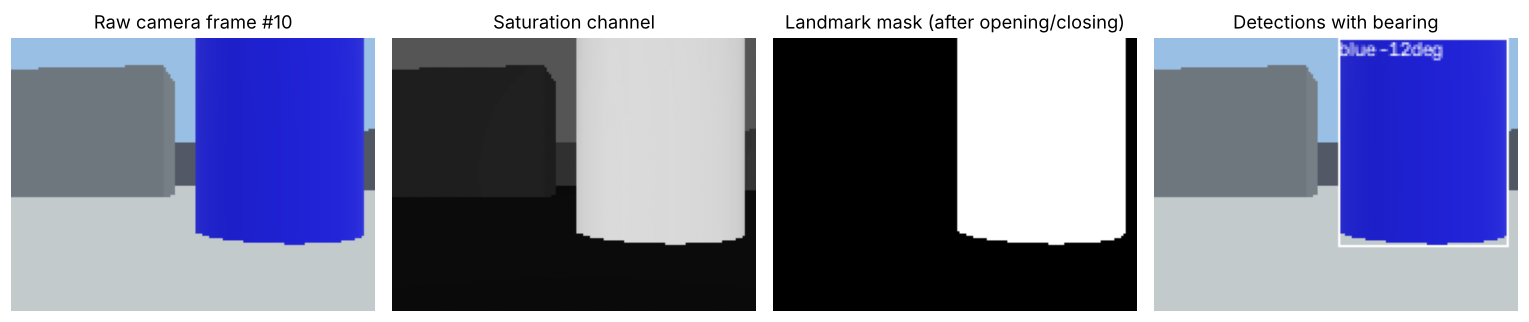

,colour,cx,cy,area,touches_border,bearing
0,blue,117.621,44.136,6442.5,False,-0.207


In [4]:
# Pick a frame where a landmark is clearly visible to illustrate each step.
frame_scores = []
for name in scans.image:
    hsv = cv2.cvtColor(cv2.imread(str(IMAGE_DIR / name)), cv2.COLOR_BGR2HSV)
    frame_scores.append((hsv[..., 1] > 150).sum())
demo_idx = int(np.argmax(frame_scores))
demo_img = cv2.imread(str(IMAGE_DIR / scans.image[demo_idx]))
demo_hsv = cv2.cvtColor(demo_img, cv2.COLOR_BGR2HSV)
demo_det = detect_landmarks(demo_img, CAM_FOV)

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
axes[0].imshow(cv2.cvtColor(demo_img, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Raw camera frame #{demo_idx}")
axes[1].imshow(demo_hsv[..., 1], cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Saturation channel")
blurred_hsv = cv2.cvtColor(cv2.GaussianBlur(demo_img, (3, 3), 0),
                           cv2.COLOR_BGR2HSV)
combined = np.zeros_like(demo_hsv[..., 0])
for colour in LANDMARK_CODES:
    combined |= colour_mask(blurred_hsv, colour)
axes[2].imshow(combined, cmap="gray")
axes[2].set_title("Landmark mask (after opening/closing)")
axes[3].imshow(cv2.cvtColor(draw_detections(demo_img, demo_det),
                            cv2.COLOR_BGR2RGB))
axes[3].set_title("Detections with bearing")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "q1_camera_pipeline.png", bbox_inches="tight")
plt.show()

pd.DataFrame([{k: (round(v, 3) if isinstance(v, float) else v)
               for k, v in d.items() if k != "bbox"} for d in demo_det])

## 3. LiDAR preprocessing

Returns beyond the 1.5 m maximum range, or closer than the 5 cm minimum, carry
no surface information and are marked invalid. A **3-ray median filter** was
also considered for removing noise spikes. The plot below compares a raw scan
with its median-filtered version, and Section 4 tests whether the filter
actually improves the map.

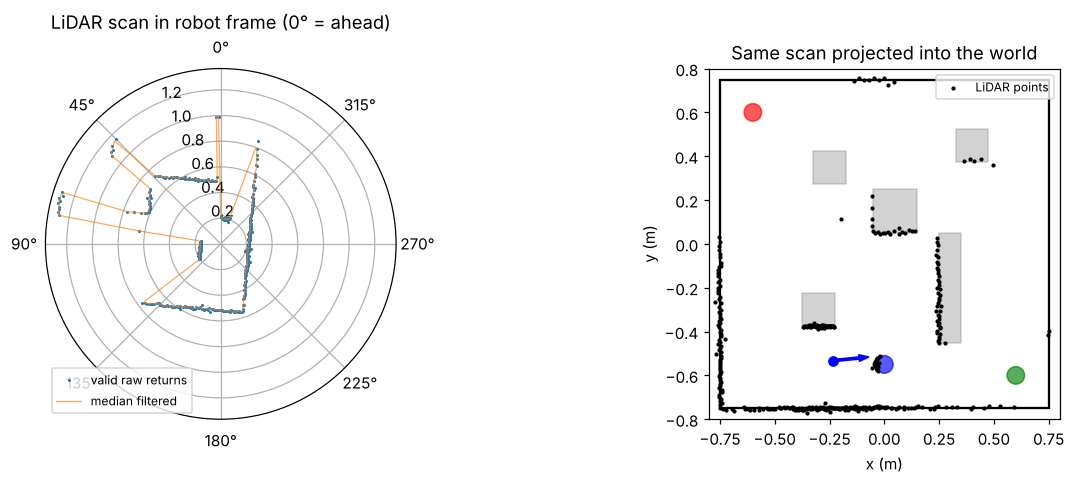

In [5]:
k = demo_idx
pose = tuple(scans.loc[k, ["x", "y", "yaw"]])
cleaned = clean_scan(raw_ranges[k], MAX_RANGE)
filtered = clean_scan(raw_ranges[k], MAX_RANGE, use_median=True)

fig = plt.figure(figsize=(12, 4.5))
ax1 = fig.add_subplot(1, 2, 1, projection="polar")
ax1.plot(angles, cleaned, ".", ms=2, label="valid raw returns")
ax1.plot(angles, filtered, "-", lw=0.8, alpha=0.7, label="median filtered")
ax1.set_theta_zero_location("N")   # robot heading points up
ax1.set_title("LiDAR scan in robot frame (0° = ahead)")
ax1.legend(loc="lower left", fontsize=8)

ax2 = fig.add_subplot(1, 2, 2)
draw_world(ax2, truth)
pts = scan_to_points(cleaned, pose, angles)
ax2.scatter(pts[:, 0], pts[:, 1], s=3, c="k", label="LiDAR points")
ax2.plot(*pose[:2], "bo")
ax2.arrow(pose[0], pose[1], 0.12 * math.cos(pose[2]),
          0.12 * math.sin(pose[2]), width=0.01, color="b")
ax2.set_xlim(-0.8, 0.8)
ax2.set_ylim(-0.8, 0.8)
ax2.set_title("Same scan projected into the world")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "q1_lidar_scan.png", bbox_inches="tight")
plt.show()

## 4. Occupancy-grid mapping (LiDAR)

The arena is divided into **2 cm cells**. For every scan, each ray is traced
with Bresenham's line algorithm. Cells the ray passes through receive "free"
evidence, and the cell where it ends receives "occupied" evidence. Evidence is
summed in **log-odds**, so repeated observations reinforce each other and
later free observations can erase earlier false hits. Cells never crossed by
a ray stay **unknown**. That distinction matters for safe planning, because
unknown space should not be treated as free.

*Note:* scans are placed using the robot's true pose from the Webots
supervisor ("mapping with known poses"). A physical robot would use odometry
or SLAM, which adds pose error (see the limitations section below).

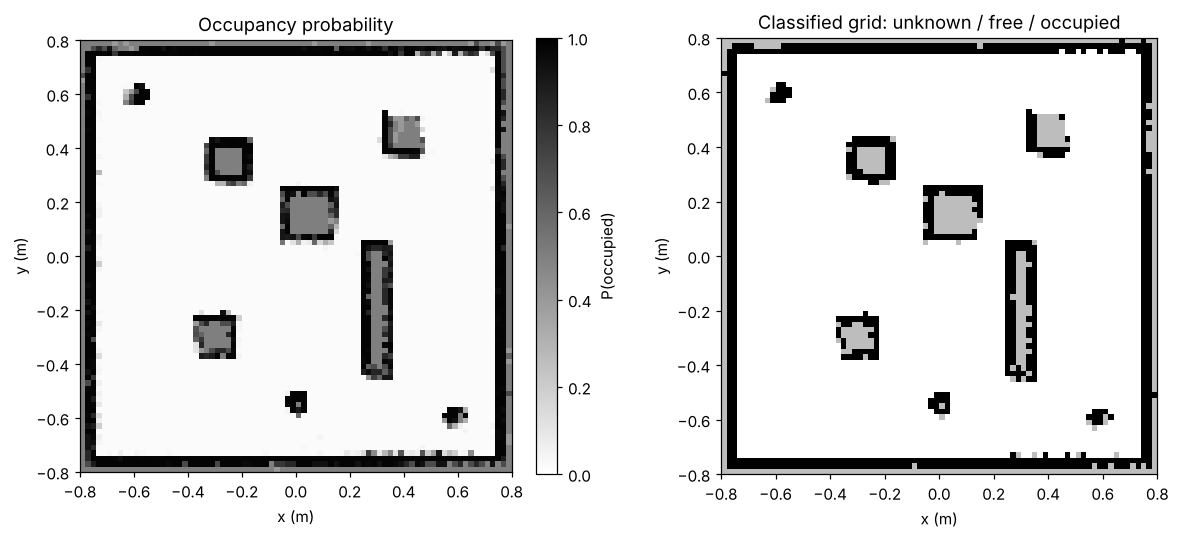

In [6]:
def build_grid(ranges_matrix, use_median=False):
    grid = OccupancyGrid(-0.8, -0.8, 1.6, 1.6, resolution=0.02)
    for i in range(len(scans)):
        pose_i = tuple(scans.loc[i, ["x", "y", "yaw"]])
        r = clean_scan(ranges_matrix[i], MAX_RANGE, use_median=use_median)
        grid.update(pose_i, r, angles, MAX_RANGE)
    return grid


grid = build_grid(raw_ranges, use_median=False)
classified = grid.classify()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
im = axes[0].imshow(grid.probability(), origin="lower", extent=grid.extent(),
                    cmap="gray_r", vmin=0, vmax=1)
fig.colorbar(im, ax=axes[0], fraction=0.046, label="P(occupied)")
axes[0].set_title("Occupancy probability")
cmap3 = ListedColormap(["#bdbdbd", "white", "black"])
axes[1].imshow(classified, origin="lower", extent=grid.extent(), cmap=cmap3,
               vmin=-1, vmax=1)
axes[1].set_title("Classified grid: unknown / free / occupied")
for a in axes:
    a.set_xlabel("x (m)")
    a.set_ylabel("y (m)")
plt.tight_layout()
plt.savefig(OUT_DIR / "q1_occupancy_grid.png", bbox_inches="tight")
plt.show()

### Map accuracy and the median-filter decision

- **Precision:** the fraction of occupied cells that lie on, or within one cell of, a real wall, obstacle or landmark.
- **False occupied cells:** occupied cells with no real object nearby.
- **Edge coverage:** the fraction of true object boundary cells detected. LiDAR cannot see inside boxes, so only boundaries are scored.

To decide whether to use the median filter, maps were built with and without
it. The test was run on the real data, and again after replacing a random 2%
and 5% of all LiDAR returns with spurious ranges, to simulate a sensor
with reflection or dropout errors.

In [7]:
truth_grid = ground_truth_grid(grid, truth)
truth_near = binary_dilation(truth_grid, iterations=1)
truth_edge = truth_grid & ~binary_erosion(truth_grid)


def map_metrics(cls):
    occ = cls == 1
    return {"Precision": round((occ & truth_near).sum() / max(occ.sum(), 1), 3),
            "False occupied cells": int((occ & ~truth_near).sum()),
            "Edge coverage": round((binary_dilation(occ, iterations=1)
                                    & truth_edge).sum() / truth_edge.sum(), 3),
            "Unknown fraction": round((cls == -1).mean(), 3)}


rng = np.random.default_rng(0)   # fixed seed: reproducible test
rows = []
for outlier_fraction in [0.0, 0.02, 0.05]:
    noisy = raw_ranges.copy()
    mask = rng.random(noisy.shape) < outlier_fraction
    noisy[mask] = rng.uniform(0.05, 1.4, mask.sum())
    for use_median in [False, True]:
        g = grid if (outlier_fraction == 0 and not use_median)             else build_grid(noisy, use_median)
        rows.append({"Outlier spikes": f"{outlier_fraction:.0%}",
                     "Median filter": "yes" if use_median else "no",
                     **map_metrics(g.classify())})
robustness = pd.DataFrame(rows)
robustness

,Outlier spikes,Median filter,Precision,False occupied cells,Edge coverage,Unknown fraction
0,0%,no,1.000,0,0.960,0.085
1,0%,yes,0.999,1,0.865,0.105
2,2%,no,1.000,0,0.916,0.036
3,2%,yes,0.999,1,0.879,0.099
4,5%,no,1.000,0,0.814,0.022
5,5%,yes,1.000,0,0.877,0.083


**Interpretation.** The log-odds grid rejects false hits on its own: spurious
returns land in random cells and are outvoted by the many "free" observations
of those cells, so false occupied cells stay near zero in every case. The
median filter's only effect on the clean data is to round off corners and
lower edge coverage, because the simulated noise (5 mm) is already well below
the 2 cm cell size. The filter only helps once outlier spikes become common
(around 5%), where spikes start to erase real surfaces. **The final map
therefore uses validity-checked raw ranges.** The filter remains available
(`use_median=True`) for noisier sensors.

## 5. Sensor fusion: camera identity + LiDAR range

For every frame, each camera detection gives a **colour** and a **bearing**.
The LiDAR rays within ±2° of that bearing are selected, and their nearest
return is taken as the range to the landmark's surface. Adding the cylinder
radius (4 cm) gives the range to its centre. Bearing plus range plus robot pose
gives a world position labelled with the camera's colour.

Detections touching the image border are discarded, because a partly visible
blob has a biased centroid. Per-frame estimates are combined with a **median**,
which is robust to occasional wrong associations, for example when another
object is in front of the landmark.

In [8]:
estimates = {c: [] for c in LANDMARK_CODES}
detections_per_colour = {c: 0 for c in LANDMARK_CODES}
frames_with_detection = 0

for i in range(len(scans)):
    pose_i = tuple(scans.loc[i, ["x", "y", "yaw"]])
    r = clean_scan(raw_ranges[i], MAX_RANGE)
    dets = detect_landmarks(cv2.imread(str(IMAGE_DIR / scans.image[i])),
                            CAM_FOV)
    frames_with_detection += bool(dets)
    for d in dets:
        detections_per_colour[d["colour"]] += 1
        p = fuse_detection(d, r, angles, pose_i, LANDMARK_RADIUS)
        if p is not None:
            estimates[d["colour"]].append(p)

landmarks = aggregate_landmarks(estimates)

rows = []
for lm_true in truth["landmarks"]:
    c = lm_true["colour"]
    est = landmarks.get(c)
    rows.append({
        "Landmark": c,
        "Camera detections": detections_per_colour[c],
        "Fused estimates": est["n_frames"] if est else 0,
        "Estimated (x, y)": f"({est['x']:.3f}, {est['y']:.3f})" if est else "-",
        "True (x, y)": f"({lm_true['x']:.3f}, {lm_true['y']:.3f})",
        "Position error (mm)": round(1000 * math.hypot(
            est["x"] - lm_true["x"], est["y"] - lm_true["y"]), 1)
        if est else None,
        "Spread (mm)": round(1000 * est["median_spread_m"], 1) if est else None,
    })
print(f"Frames containing at least one landmark: "
      f"{frames_with_detection} of {len(scans)}")
landmark_table = pd.DataFrame(rows)
landmark_table

Frames containing at least one landmark: 76 of 182


,Landmark,Camera detections,Fused estimates,"Estimated (x, y)","True (x, y)",Position error (mm),Spread (mm)
0,red,45,37,"(-0.602, 0.596)","(-0.600, 0.600)",4.3,6.9
1,green,20,15,"(0.594, -0.600)","(0.600, -0.600)",6.3,17.3
2,blue,17,11,"(-0.004, -0.557)","(0.000, -0.550)",8.2,3.7


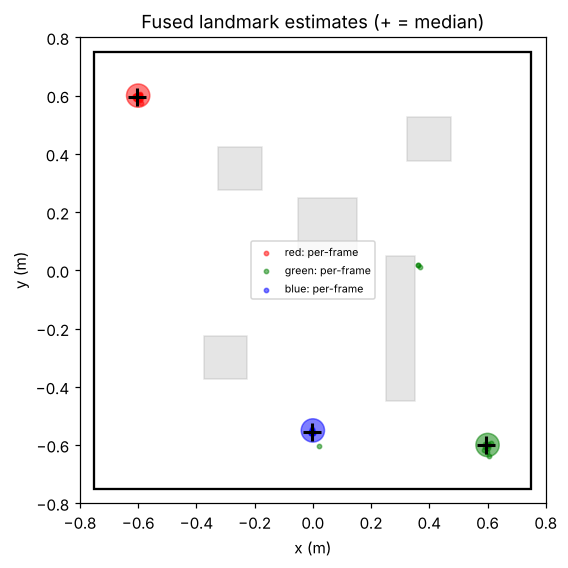

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
draw_world(ax, truth, alpha=0.2)
for c, pts in estimates.items():
    if pts:
        pts = np.array(pts)
        ax.scatter(pts[:, 0], pts[:, 1], s=8, color=c, alpha=0.5,
                   label=f"{c}: per-frame")
for c, lm in landmarks.items():
    ax.plot(lm["x"], lm["y"], "k+", ms=12, mew=2)
ax.set_xlim(-0.8, 0.8)
ax.set_ylim(-0.8, 0.8)
ax.set_title("Fused landmark estimates (+ = median)")
ax.legend(fontsize=7, loc="center")
plt.savefig(OUT_DIR / "q1_landmark_estimates.png", bbox_inches="tight")
plt.show()

## 6. Unified environment representation

The LiDAR occupancy grid and the fused landmarks are merged into one
**semantic occupancy grid**. Occupied cells near a fused landmark are
relabelled with that landmark's colour, giving one map that records both
*where* things are (from the LiDAR) and *what* they are (from the camera).

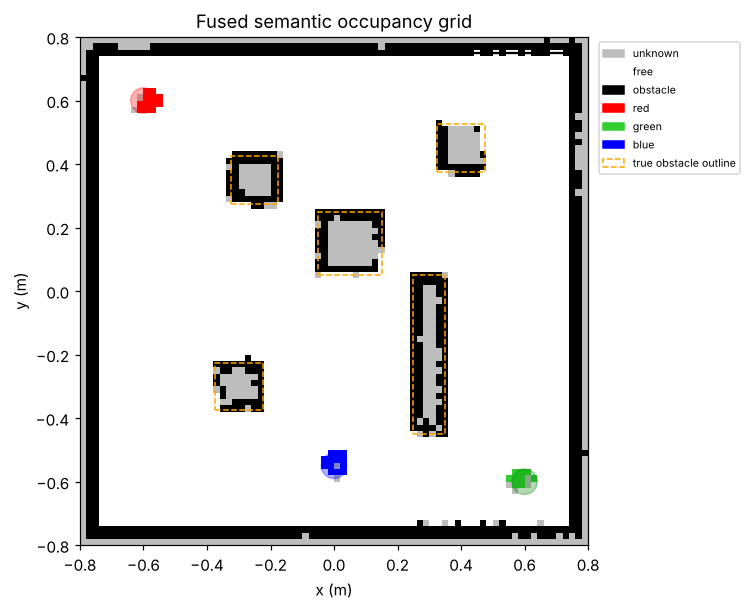

{'unknown': 545, 'free': 4974, 'obstacle': 847, 'red': 12, 'green': 9, 'blue': 13}


In [10]:
fused = build_fused_map(grid, classified, landmarks, LANDMARK_RADIUS)
labels = ["unknown", "free", "obstacle", "red", "green", "blue"]
fused_cmap = ListedColormap(["#bdbdbd", "white", "black",
                             "red", "limegreen", "blue"])

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(fused, origin="lower", extent=grid.extent(), cmap=fused_cmap,
          vmin=-1, vmax=4, interpolation="nearest")
draw_world(ax, truth, alpha=0.0)   # true outlines only
for o in truth["obstacles"]:
    ax.add_patch(Rectangle((o["x"] - o["size_x"] / 2,
                            o["y"] - o["size_y"] / 2),
                           o["size_x"], o["size_y"], fill=False,
                           ec="orange", lw=1, ls="--"))
handles = [Rectangle((0, 0), 1, 1, color=fused_cmap(i)) for i in range(6)]
handles.append(Rectangle((0, 0), 1, 1, fill=False, ec="orange", ls="--"))
ax.legend(handles, labels + ["true obstacle outline"], fontsize=7,
          loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Fused semantic occupancy grid")
plt.savefig(OUT_DIR / "q1_fused_map.png", bbox_inches="tight")
plt.show()

print({labels[v + 1]: int((fused == v).sum()) for v in range(-1, 5)})

In [11]:
# Save the unified map for the motion planner (Question 2).
np.savez(OUT_DIR / "fused_map.npz",
         fused=fused, classified=classified,
         probability=grid.probability(),
         x_min=grid.x_min, y_min=grid.y_min, resolution=grid.res,
         landmarks=json.dumps(landmarks))
print("Saved", OUT_DIR / "fused_map.npz", fused.shape)

Saved outputs/fused_map.npz (80, 80)


## 7. Design decisions and limitations

| Decision | Justification |
|---|---|
| HSV colour space | Saturation separates landmarks from all grey or pale background surfaces regardless of brightness; hue identifies the colour |
| Gaussian blur (3×3) and opening/closing | Suppresses aliasing on edges and isolated noise pixels before and after thresholding |
| Largest blob per colour, discard border blobs | Each colour is unique in the world; clipped blobs bias the bearing |
| Validity check, no median filter | Testing showed the filter lowers edge coverage on this data and only helps above about 5% outlier spikes; log-odds already rejects isolated false hits |
| Log-odds occupancy grid, 2 cm cells | Accumulates noisy evidence over many scans; separates free from unknown; 2 cm is fine relative to the 7.4 cm robot |
| Bearing-based association (±2°) | The camera gives bearing and identity, the LiDAR gives range; the narrow window avoids picking up neighbouring objects |
| Median across frames | Robust to occasional wrong associations caused by occlusion |

**Limitations**
- **Known poses:** mapping uses the supervisor's true pose. Odometry drift on a real robot would blur the map and shift landmark estimates.
- **Camera offset:** the camera sits a few centimetres ahead of the LiDAR, but both are treated as co-located. That error is small at these ranges, but it would matter for close objects.
- **Simple colour model:** fixed HSV thresholds rely on the controlled lighting and distinct colours of this world. Real environments would need adaptive thresholds or a learned detector.
- **Coverage:** areas the robot never observed stay unknown, so the planner must treat them as untraversable or explore them first.